# CardioIA — Fase 4: Coração em Imagens 🫀
## Diagnóstico com Visão Computacional — Partes 1 e 2

**Equipe:** João Pedro Santos Azevedo (RM566701) · Miriã Leal Mantovani (RM567811)
**Turma:** 2TIAOR-2026

**Objetivo:** construir um protótipo de Assistente Cardiológico Virtual que classifica imagens de eletrocardiograma (ECG) de 12 derivações em 4 classes, comparando uma CNN treinada do zero com Transfer Learning (ResNet50).

> ⚠️ **Aviso:** protótipo acadêmico. Não é dispositivo médico e não substitui a avaliação de um cardiologista.

### Por que este dataset?
Usamos o **ECG Images dataset of Cardiac Patients** (Khan & Hussain, 2021 — Mendeley Data, DOI 10.17632/gwbz3fsgp8.2), coletado no Ch. Pervaiz Elahi Institute of Cardiology (Multan, Paquistão).

| Classe | Arquivos | Imagens **distintas** |
|---|---|---|
| Normal | 284 | 142 |
| Infarto agudo do miocárdio (IAM) | 239 | **30** |
| Batimento anormal | 233 | 233 |
| Histórico de IAM | 172 | 86 |

> ⚠️ **O dataset é duplicado.** Os 928 arquivos correspondem a apenas 491 imagens distintas —
> na classe IAM, cada imagem aparece oito vezes. A seção 1.2b mede isso, e é o fato que
> explica os resultados da Parte 2. A coluna da direita é a que vale.

Escolhemos este dataset em vez do NIH Chest X-ray por três motivos:
1. **Aderência ao tema:** o ECG é o exame cardiológico mais comum. No NIH, a única classe cardíaca (cardiomegalia) é uma fração pequena do dataset.
2. **Viabilidade:** cerca de 930 imagens cabem no Colab. O NIH completo tem cerca de 42 GB.
3. **Balanceamento aparente:** pelas contagens de arquivo, a classe menor teria cerca de 60% do tamanho da maior. Depois de deduplicar, a razão real é de 7,8x — ver seção 1.2b.

**Limitação conhecida:** o dataset não traz idade ou sexo dos pacientes e vem de um único hospital. Isso limita a generalização e a análise de fairness (ver seção final).

### Como rodar

O notebook detecta sozinho se está no Colab ou numa máquina local.

**No Google Colab**
1. Ambiente de execução → Alterar tipo de ambiente → **GPU (T4)**.
2. Baixe o zip em https://data.mendeley.com/datasets/gwbz3fsgp8/2 (*Download All*).
3. Suba o zip para `MyDrive/CardioIA/`.
4. Execute as células em ordem.

**No VS Code (local)**
1. Crie o ambiente e instale as dependências, a partir da raiz do repositório:
   ```bash
   python -m venv .venv
   .venv\Scripts\activate      # Windows   (no macOS/Linux: source .venv/bin/activate)
   pip install -r requirements.txt
   ```
2. Baixe o mesmo zip do Mendeley e coloque-o em **`dados/`** na raiz do repositório.
3. Selecione o kernel `.venv` no canto superior direito do notebook.
4. Execute as células em ordem.

> **Sobre a GPU:** sem placa NVIDIA com CUDA, o TensorFlow usa a CPU. O treino continua
> funcionando, mas em vez de ~20 minutos leva algumas horas. Se for rodar na CPU, reduza
> as épocas (`epochs=50` → `15` na CNN e `25` → `8` no fine-tuning) antes de começar — a
> parada antecipada já interrompe o treino quando a validação para de melhorar, mas o teto
> alto de épocas é caro mesmo assim.

## 0. Configuração do ambiente

In [1]:
import os, sys, random, json, hashlib, shutil, zipfile, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix, accuracy_score,
                             precision_recall_fscore_support)
from sklearn.utils.class_weight import compute_class_weight

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

IMG_SIZE = 224          # entrada padrão das redes pré-treinadas no ImageNet
BATCH = 32
CROP_TOP = 0.10         # fração superior recortada (cabeçalho com texto) — ver Parte 1.3

# O mesmo notebook roda no Colab e localmente: detectamos o ambiente em vez de
# manter duas versões do arquivo, que inevitavelmente divergiriam.
try:
    import google.colab          # noqa: F401
    EM_COLAB = True
except ImportError:
    EM_COLAB = False

if EM_COLAB:
    BASE_DIR = '/content'
else:
    # Funciona com o notebook aberto a partir de notebooks/ ou da raiz do repositório.
    _aqui = os.path.abspath('')
    BASE_DIR = os.path.dirname(_aqui) if os.path.basename(_aqui) == 'notebooks' else _aqui

RAW_DIR  = os.path.join(BASE_DIR, 'raw')          # dataset extraído
PROC_DIR = os.path.join(BASE_DIR, 'processed')    # imagens pré-processadas
OUT_DIR  = os.path.join(BASE_DIR, 'outputs')      # prints, métricas e modelos
os.makedirs(OUT_DIR, exist_ok=True)

# Nomes internos (sem acento, usados como pastas) e nomes de exibição
CLASSES = ['Normal', 'Batimento_anormal', 'Historico_IAM', 'IAM']
DISPLAY = {'Normal': 'Normal',
           'Batimento_anormal': 'Batimento anormal',
           'Historico_IAM': 'Histórico de infarto',
           'IAM': 'Infarto agudo do miocárdio'}

print('Ambiente :', 'Google Colab' if EM_COLAB else 'local (VS Code)')
print('Base     :', BASE_DIR)
print('TensorFlow', tf.__version__)
gpus = tf.config.list_physical_devices('GPU')
print('GPU      :', gpus if gpus else 'nenhuma — o treino vai rodar na CPU e demorar bem mais')

Ambiente : local (VS Code)
Base     : c:\Users\JOÃO\Downloads\cardioia-fase4
TensorFlow 2.21.0
GPU      : nenhuma — o treino vai rodar na CPU e demorar bem mais


# PARTE 1 — Pré-processamento e organização das imagens

## 1.1 Aquisição dos dados
O zip do Mendeley pode conter zips internos, e alguns espelhos do dataset já vêm separados em `train/test`. Por isso a extração é recursiva e o rótulo é inferido pelo nome das pastas. Depois juntamos tudo e refazemos o split nós mesmos, de forma estratificada.

In [ ]:
# Localiza o zip do dataset. No Colab ele vem do Drive; localmente, da pasta dados/.
if EM_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    ORIGEM = '/content/drive/MyDrive/CardioIA'
else:
    ORIGEM = os.path.join(BASE_DIR, 'dados')
    os.makedirs(ORIGEM, exist_ok=True)

zips = glob.glob(os.path.join(ORIGEM, '*.zip'))
assert zips, (
    f'Nenhum .zip encontrado em {ORIGEM}.\n'
    'Baixe o dataset em https://data.mendeley.com/datasets/gwbz3fsgp8/2 '
    '(botão "Download All") e coloque o arquivo nessa pasta.'
)
print('Zip encontrado:', zips[0])

def extract_nested(zip_path, dest):
    # Extrai o zip e, em seguida, qualquer zip que estiver dentro dele.
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(dest)
    while True:
        pending = [p for p in glob.glob(os.path.join(dest, '**', '*.zip'), recursive=True)
                   if not os.path.exists(p[:-4])]
        if not pending:
            break
        for p in pending:
            with zipfile.ZipFile(p) as z:
                z.extractall(p[:-4])

if not os.path.exists(RAW_DIR):
    extract_nested(zips[0], RAW_DIR)
print('Extração concluída em', RAW_DIR)

## 1.2 Inventário: rótulos, duplicatas e distribuição das classes

In [ ]:
def map_folder(name):
    # Converte o nome de uma pasta na classe correspondente (ou None).
    n = name.lower().strip()
    if 'history' in n or n in ('hmi', 'pmi'):
        return 'Historico_IAM'
    if 'myocardial' in n or n == 'mi':
        return 'IAM'
    if 'abnormal' in n or n == 'ahb':
        return 'Batimento_anormal'
    if 'normal' in n:            # testado depois de 'abnormal' de propósito
        return 'Normal'
    return None

def label_from_path(path):
    # Procura a classe da pasta mais próxima do arquivo até a raiz.
    for part in reversed(path.split(os.sep)[:-1]):
        lab = map_folder(part)
        if lab:
            return lab
    return None

EXTS = ('.jpg', '.jpeg', '.png', '.bmp')
files = [p for p in glob.glob(os.path.join(RAW_DIR, '**', '*'), recursive=True)
         if p.lower().endswith(EXTS)]

def md5(path):
    with open(path, 'rb') as f:
        return hashlib.md5(f.read()).hexdigest()

df = pd.DataFrame({'path': files})
df['label'] = df['path'].apply(label_from_path)

if df['label'].isna().any():
    print('⚠️ Pastas sem classe reconhecida:')
    print(sorted({os.path.basename(os.path.dirname(p)) for p in df[df.label.isna()].path}))
df = df.dropna(subset=['label']).reset_index(drop=True)

# Duplicatas exatas vazariam informação do treino para o teste
df['hash'] = df['path'].apply(md5)
n_antes = len(df)
df = df.drop_duplicates('hash').reset_index(drop=True)
print(f'Imagens: {n_antes} -> {len(df)} após remover {n_antes - len(df)} duplicatas exatas')

assert set(df.label) == set(CLASSES), f'Classes encontradas: {set(df.label)}'
counts = df['label'].value_counts().reindex(CLASSES)
print(counts)

plt.figure(figsize=(7, 3.5))
sns.barplot(x=[DISPLAY[c] for c in CLASSES], y=counts.values, color='#c0392b')
plt.title('Distribuição das classes (dataset completo)')
plt.ylabel('Nº de imagens'); plt.xticks(rotation=15)
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/01_distribuicao_classes.png', dpi=150); plt.show()

In [ ]:
# Tamanho e modo de cor das imagens originais (amostra)
amostra = df.sample(min(60, len(df)), random_state=SEED)
info = []
for p in amostra.path:
    with Image.open(p) as im:
        info.append((im.size[0], im.size[1], im.mode))
info = pd.DataFrame(info, columns=['largura', 'altura', 'modo'])
print(info.describe(include='all'))

# Um exemplo de cada classe
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, c in zip(axes, CLASSES):
    p = df[df.label == c].path.iloc[0]
    ax.imshow(Image.open(p)); ax.set_title(DISPLAY[c]); ax.axis('off')
plt.suptitle('Imagens originais'); plt.tight_layout()
plt.savefig(f'{OUT_DIR}/02_exemplos_originais.png', dpi=150); plt.show()

## 1.2b A descoberta que explica os resultados: o dataset é duplicado

A remoção de duplicatas por hash, na célula anterior, tirou mais imagens do que seria razoável
esperar. Vale medir o tamanho do problema, porque ele condiciona tudo o que vem depois.

In [ ]:
# Quantas imagens DISTINTAS existem em cada pasta do dataset original
import collections

por_classe = collections.defaultdict(list)
for p in files:                      # 'files' vem da célula 1.2
    lab = label_from_path(p)
    if lab:
        por_classe[lab].append(p)

linhas = []
for c in CLASSES:
    arqs = por_classe[c]
    hashes = collections.Counter(md5(p) for p in arqs)
    linhas.append({'classe': DISPLAY[c], 'arquivos': len(arqs),
                   'imagens_unicas': len(hashes),
                   'duplicatas': len(arqs) - len(hashes),
                   'maior_repeticao': max(hashes.values()) if hashes else 0})

dup_df = pd.DataFrame(linhas).set_index('classe')
display(dup_df)
dup_df.to_csv(f'{OUT_DIR}/duplicacao_dataset.csv')

tot_arq, tot_uni = dup_df.arquivos.sum(), dup_df.imagens_unicas.sum()
print(f'\nO dataset tem {tot_arq} arquivos, mas apenas {tot_uni} imagens distintas '
      f'({100*(tot_arq-tot_uni)/tot_arq:.0f}% de duplicação).')
print(f'Razão de desbalanceamento REAL (após deduplicar): '
      f'{dup_df.imagens_unicas.max()/dup_df.imagens_unicas.min():.1f}x')

fig, ax = plt.subplots(figsize=(9, 3.6))
y = np.arange(len(dup_df))
ax.barh(y + 0.2, dup_df.arquivos, 0.4, label='arquivos no disco', color='#d9d9d9')
ax.barh(y - 0.2, dup_df.imagens_unicas, 0.4, label='imagens distintas', color='#b3221e')
ax.set_yticks(y); ax.set_yticklabels(dup_df.index)
ax.set_xlabel('quantidade'); ax.legend()
ax.set_title('O que o dataset promete e o que ele entrega')
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/01b_duplicacao.png', dpi=150); plt.show()

**Por que isso importa mais que qualquer ajuste de hiperparâmetro.**

A deduplicação não é um capricho: sem ela, cópias byte a byte da mesma imagem cairiam em treino
e em teste, e a acurácia medida seria uma ficção — o modelo estaria sendo avaliado em imagens
que memorizou. O preço de fazer a coisa certa é ficar com um conjunto bem menor do que o
anunciado, concentrado justamente na classe clinicamente mais importante.

É por isso que as duas abordagens da Parte 2 sobreajustam, e é por isso que a seção 2.4
acrescenta uma formulação binária: não como desculpa pelo resultado de quatro classes, mas
porque é a pergunta que estes dados conseguem responder.

## 1.3 Pipeline de pré-processamento

| Etapa | O que fazemos | Justificativa |
|---|---|---|
| Conversão de cor | RGB → escala de cinza → RGB (3 canais iguais) | A informação diagnóstica está no **traçado**, não na cor do papel. Isso remove variações de tonalidade entre impressões e scans. Os 3 canais são exigidos pelas redes pré-treinadas. |
| Recorte | Remove os 10% superiores (`CROP_TOP`) | O topo do exame traz um cabeçalho com texto e dados do aparelho/paciente. Não é sinal cardíaco, pode virar atalho para o modelo (*shortcut learning*) e pode conter dado pessoal (LGPD). **Confira visualmente abaixo e ajuste se necessário.** |
| Redimensionamento | 224 × 224 px, filtro LANCZOS | É o tamanho de entrada da ResNet50/VGG16 e reduz drasticamente o custo de memória. LANCZOS preserva melhor linhas finas do traçado. |
| Conversão de formato | JPG → PNG | Formato sem perda: o arquivo processado não ganha novos artefatos de compressão. |
| Normalização | `[0,255] → [0,1]` (CNN do zero) e subtração da média do ImageNet (ResNet50) | Feita **como camada dentro do modelo**. Assim, o protótipo recebe a imagem crua e aplica exatamente a mesma normalização do treino, sem risco de divergência. |
| Divisão | 70% treino / 15% validação / 15% teste, estratificada | A estratificação mantém a proporção das classes em cada conjunto. O teste fica isolado até a avaliação final. |
| Aumento de dados | Rotação ±7°, zoom 8%, translação 4%, contraste 15% — **só no treino** | Simula pequenas variações de escaneamento. **Não usamos espelhamento**: inverter um ECG troca a ordem das derivações e o sentido do tempo, criando um exame fisiologicamente impossível. |

In [ ]:
def preprocess_pil(img, size=IMG_SIZE, crop_top=CROP_TOP):
    # Mesma função usada no treino e no protótipo.
    img = img.convert('L')
    w, h = img.size
    img = img.crop((0, int(h * crop_top), w, h))
    img = img.resize((size, size), Image.LANCZOS)
    return img.convert('RGB')

def preprocess_path(path):
    with Image.open(path) as im:
        return preprocess_pil(im)

# Antes x depois
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for i, c in enumerate(CLASSES):
    p = df[df.label == c].path.iloc[0]
    axes[0, i].imshow(Image.open(p)); axes[0, i].set_title(f'Original — {DISPLAY[c]}')
    axes[1, i].imshow(preprocess_path(p)); axes[1, i].set_title('Pré-processada 224×224')
    for ax in axes[:, i]: ax.axis('off')
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/03_antes_depois.png', dpi=150); plt.show()

## 1.4 Divisão estratificada em treino, validação e teste

In [ ]:
train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df.label, random_state=SEED)
val_df, test_df   = train_test_split(temp_df, test_size=0.50, stratify=temp_df.label, random_state=SEED)

splits = {'train': train_df, 'val': val_df, 'test': test_df}
resumo = pd.DataFrame({k: v.label.value_counts().reindex(CLASSES) for k, v in splits.items()})
resumo.loc['Total'] = resumo.sum()
print(resumo)

In [ ]:
# Grava as imagens processadas em processed/<split>/<classe>/<hash>.png
if os.path.exists(PROC_DIR):
    shutil.rmtree(PROC_DIR)

registros = []
for split, d in splits.items():
    for _, row in d.iterrows():
        dest_dir = os.path.join(PROC_DIR, split, row.label)
        os.makedirs(dest_dir, exist_ok=True)
        dest = os.path.join(dest_dir, row.hash + '.png')
        preprocess_path(row.path).save(dest)
        registros.append({'split': split, 'label': row.label, 'origem': row.path, 'processada': dest})

manifest = pd.DataFrame(registros)
manifest.to_csv(f'{OUT_DIR}/manifest_splits.csv', index=False)
print('Imagens processadas:', len(manifest))

# Conferência: nenhuma imagem aparece em dois conjuntos
h = {s: set(d.hash) for s, d in splits.items()}
assert not (h['train'] & h['val']) and not (h['train'] & h['test']) and not (h['val'] & h['test'])
print('✅ Sem vazamento entre treino, validação e teste.')

## 1.5 Carregamento eficiente (tf.data), normalização e aumento de dados

In [ ]:
def make_ds(split, shuffle):
    ds = keras.utils.image_dataset_from_directory(
        os.path.join(PROC_DIR, split), labels='inferred', label_mode='int',
        class_names=CLASSES, image_size=(IMG_SIZE, IMG_SIZE), batch_size=BATCH,
        shuffle=shuffle, seed=SEED)
    return ds.cache().prefetch(tf.data.AUTOTUNE)

train_ds = make_ds('train', shuffle=True)
val_ds   = make_ds('val',   shuffle=False)
test_ds  = make_ds('test',  shuffle=False)   # sem embaralhar: rótulos alinhados às predições

def make_augment():
    return keras.Sequential([
        layers.RandomRotation(0.02),             # ±0,02 volta ≈ ±7°
        layers.RandomZoom(0.08),
        layers.RandomTranslation(0.04, 0.04),
        layers.RandomContrast(0.15),
    ], name='aumento_de_dados')                   # ativo apenas em training=True

# Pesos por classe: compensam o desbalanceamento (Histórico de IAM é a menor)
y_train = train_df.label.map(CLASSES.index).values
cw = compute_class_weight('balanced', classes=np.arange(len(CLASSES)), y=y_train)
CLASS_WEIGHT = dict(enumerate(cw))
print('Pesos por classe:', {CLASSES[k]: round(v, 2) for k, v in CLASS_WEIGHT.items()})

# Demonstração da normalização
x, _ = next(iter(train_ds))
x_norm = layers.Rescaling(1. / 255)(x)
print(f'Pixels antes: [{x.numpy().min():.0f}, {x.numpy().max():.0f}] | '
      f'depois: [{x_norm.numpy().min():.2f}, {x_norm.numpy().max():.2f}]')

# Visualização do aumento de dados
aug = make_augment()
plt.figure(figsize=(14, 3.5))
for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(aug(x[:1], training=True)[0].numpy().astype('uint8')); plt.axis('off')
plt.suptitle('Aumento de dados aplicado à mesma imagem'); plt.tight_layout()
plt.savefig(f'{OUT_DIR}/04_aumento_dados.png', dpi=150); plt.show()

# PARTE 2 — Classificação com CNN

## Funções de avaliação compartilhadas
Métricas usadas: acurácia, precisão, recall, F1 por classe e médias *macro*, além da matriz de confusão. No contexto clínico, damos atenção especial ao **recall de IAM**: um infarto não detectado (falso negativo) é o erro mais grave.

In [ ]:
def plot_history(histories, name):

    hist = {}

    for h in histories:

        for k, v in h.history.items():

            hist.setdefault(k, []).extend(v)

    fig, ax = plt.subplots(1, 2, figsize=(12, 4))

    for i, m in enumerate(['accuracy', 'loss']):

        ax[i].plot(hist[m], label='treino'); ax[i].plot(hist['val_' + m], label='validação')

        ax[i].set_title(f'{name} — {m}'); ax[i].set_xlabel('época'); ax[i].legend()

    if len(histories) > 1:

        for a in ax: a.axvline(len(histories[0].history['loss']) - 0.5, ls='--', c='gray')

    plt.tight_layout(); plt.savefig(f'{OUT_DIR}/{name}_curvas.png', dpi=150); plt.show()



def evaluate(model, ds, name, split='teste', plot=True):

    y_true = np.concatenate([y.numpy() for _, y in ds])

    probs = model.predict(ds, verbose=0)

    y_pred = probs.argmax(1)

    labels = [DISPLAY[c] for c in CLASSES]

    rep = classification_report(y_true, y_pred, target_names=labels, digits=3)

    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, average='macro', zero_division=0)

    _, r_cls, _, _ = precision_recall_fscore_support(y_true, y_pred, labels=range(len(CLASSES)),

                                                    zero_division=0)

    res = {'modelo': name, 'conjunto': split, 'acuracia': accuracy_score(y_true, y_pred),

           'precisao_macro': p, 'recall_macro': r, 'f1_macro': f,

           'recall_IAM': r_cls[CLASSES.index('IAM')]}

    if plot:

        print(f'===== {name} — {split} =====\n{rep}')

        with open(f'{OUT_DIR}/{name}_{split}_relatorio.txt', 'w', encoding='utf-8') as fh:

            fh.write(rep)

        cm = confusion_matrix(y_true, y_pred)

        plt.figure(figsize=(6.5, 5.5))

        sns.heatmap(cm, annot=True, fmt='d', cmap='Reds', xticklabels=labels, yticklabels=labels)

        plt.xlabel('Previsto'); plt.ylabel('Real')

        plt.title(f'Matriz de confusão — {name} ({split})')

        plt.xticks(rotation=30, ha='right'); plt.tight_layout()

        plt.savefig(f'{OUT_DIR}/{name}_{split}_matriz_confusao.png', dpi=150); plt.show()

    return res



def callbacks(name, patience=8):

    return [keras.callbacks.EarlyStopping(monitor='val_loss', patience=patience,

                                          restore_best_weights=True),

            keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3,

                                              min_lr=1e-6),

            keras.callbacks.ModelCheckpoint(f'{OUT_DIR}/{name}.keras', monitor='val_loss',

                                            save_best_only=True)]

## 2.1 Abordagem 1 — CNN simples treinada do zero
Arquitetura: 4 blocos `Conv2D → BatchNorm → MaxPool` com 32, 64, 128 e 256 filtros, seguidos de `GlobalAveragePooling` e `Dropout(0.4)`.

- **BatchNorm** estabiliza e acelera o treino.
- **GlobalAveragePooling**, em vez de `Flatten`, reduz muito o número de parâmetros. Isso é importante porque temos só cerca de 650 imagens de treino e o risco de overfitting é alto.

In [ ]:
def build_cnn():
    inputs = keras.Input((IMG_SIZE, IMG_SIZE, 3))
    x = make_augment()(inputs)
    x = layers.Rescaling(1. / 255, name='normalizacao_0_1')(x)
    for f in [32, 64, 128, 256]:
        x = layers.Conv2D(f, 3, padding='same', activation='relu')(x)
        x = layers.BatchNormalization()(x)
        x = layers.MaxPooling2D()(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.4)(x)
    outputs = layers.Dense(len(CLASSES), activation='softmax')(x)
    return keras.Model(inputs, outputs, name='cnn_do_zero')

cnn = build_cnn()
cnn.compile(optimizer=keras.optimizers.Adam(1e-3),
            loss='sparse_categorical_crossentropy', metrics=['accuracy'])
cnn.summary()

h_cnn = cnn.fit(train_ds, validation_data=val_ds, epochs=50,
                class_weight=CLASS_WEIGHT, callbacks=callbacks('cnn_do_zero'))
plot_history([h_cnn], 'cnn_do_zero')

In [ ]:
res_cnn_val  = evaluate(cnn, val_ds,  'cnn_do_zero', 'validacao', plot=False)
res_cnn_test = evaluate(cnn, test_ds, 'cnn_do_zero', 'teste')

## 2.2 Abordagem 2 — Transfer Learning com ResNet50 (ImageNet)
O treino é feito em duas etapas:

1. **Extração de características:** a ResNet50 fica congelada e treinamos só a nova cabeça classificadora (LR 1e-3).
2. **Fine-tuning:** descongelamos o último bloco (`conv5`) e treinamos com LR baixo (1e-5). Assim a rede adapta os filtros de alto nível ao traçado do ECG sem destruir o que aprendeu no ImageNet.

As camadas de BatchNorm ficam em modo de inferência, como recomenda a documentação do Keras para fine-tuning.

**Normalização da ResNet50:** o `preprocess_input` original converte RGB→BGR e subtrai a média do ImageNet. Como nossas imagens têm 3 canais idênticos, a troca de canais não altera nada. Basta subtrair a média, o que fazemos com uma camada `Normalization` serializável. Assim o modelo salvo carrega sem `Lambda` e sem código customizado.

In [ ]:
from tensorflow.keras.applications import ResNet50

def build_transfer():
    base = ResNet50(include_top=False, weights='imagenet', input_shape=(IMG_SIZE, IMG_SIZE, 3))
    base.trainable = False
    inputs = keras.Input((IMG_SIZE, IMG_SIZE, 3))
    x = make_augment()(inputs)
    x = layers.Normalization(mean=[103.939, 116.779, 123.68], variance=[1., 1., 1.],
                             name='normalizacao_imagenet')(x)
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(len(CLASSES), activation='softmax')(x)
    return keras.Model(inputs, outputs, name='resnet50_transfer'), base

tl, base = build_transfer()
tl.compile(optimizer=keras.optimizers.Adam(1e-3),
           loss='sparse_categorical_crossentropy', metrics=['accuracy'])
h_tl1 = tl.fit(train_ds, validation_data=val_ds, epochs=15, class_weight=CLASS_WEIGHT,
               callbacks=callbacks('resnet50_transfer', patience=5))

In [ ]:
# Etapa 2 — fine-tuning do bloco conv5
base.trainable = True
for layer in base.layers:
    layer.trainable = layer.name.startswith('conv5') and not isinstance(layer, layers.BatchNormalization)
print('Camadas treináveis na base:', sum(l.trainable for l in base.layers))

tl.compile(optimizer=keras.optimizers.Adam(1e-5),
           loss='sparse_categorical_crossentropy', metrics=['accuracy'])
h_tl2 = tl.fit(train_ds, validation_data=val_ds, epochs=25, class_weight=CLASS_WEIGHT,
               callbacks=callbacks('resnet50_transfer', patience=6))
plot_history([h_tl1, h_tl2], 'resnet50_transfer')

In [ ]:
res_tl_val  = evaluate(tl, val_ds,  'resnet50_transfer', 'validacao', plot=False)
res_tl_test = evaluate(tl, test_ds, 'resnet50_transfer', 'teste')

## 2.3 Comparação entre as abordagens
O melhor modelo é escolhido pelo **F1 macro na validação**, e não no teste. Escolher pelo teste contaminaria a estimativa final de desempenho.

In [ ]:
comp = pd.DataFrame([res_cnn_val, res_tl_val, res_cnn_test, res_tl_test]).round(3)
comp.to_csv(f'{OUT_DIR}/comparacao_modelos.csv', index=False)
display(comp)

teste = comp[comp.conjunto == 'teste'].set_index('modelo')
metricas = ['acuracia', 'precisao_macro', 'recall_macro', 'f1_macro', 'recall_IAM']
teste[metricas].T.plot.bar(figsize=(9, 4), color=['#7f8c8d', '#c0392b'])
plt.title('CNN do zero × Transfer Learning (conjunto de teste)'); plt.ylim(0, 1.05)
plt.xticks(rotation=0); plt.legend(title=''); plt.tight_layout()
plt.savefig(f'{OUT_DIR}/05_comparacao_modelos.png', dpi=150); plt.show()

best_name = 'resnet50_transfer' if res_tl_val['f1_macro'] >= res_cnn_val['f1_macro'] else 'cnn_do_zero'
best = tl if best_name == 'resnet50_transfer' else cnn
print('Modelo escolhido para o protótipo:', best_name)

In [ ]:
# Galeria de predições no teste (verde = acerto, vermelho = erro)
amostra_t = test_df.sample(8, random_state=SEED)
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
for ax, (_, row) in zip(axes.ravel(), amostra_t.iterrows()):
    img = preprocess_path(row.path)
    probs = best.predict(np.expand_dims(np.array(img, dtype='float32'), 0), verbose=0)[0]
    pred = CLASSES[probs.argmax()]
    ok = pred == row.label
    ax.imshow(img); ax.axis('off')
    ax.set_title(f'Real: {DISPLAY[row.label]}\nPrevisto: {DISPLAY[pred]} ({probs.max():.0%})',
                 color='green' if ok else 'red', fontsize=10)
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/06_galeria_predicoes.png', dpi=150); plt.show()

In [ ]:
# Salva o modelo final e a configuração (reaproveitados no Flask / app mobile — Ir Além 2)

best.save(f'{OUT_DIR}/cardioia_ecg_modelo.keras')

with open(f'{OUT_DIR}/cardioia_ecg_config.json', 'w', encoding='utf-8') as fh:

    json.dump({'classes': CLASSES, 'display': DISPLAY, 'img_size': IMG_SIZE,

               'crop_top': CROP_TOP, 'modelo': best_name}, fh, ensure_ascii=False, indent=2)

print('Modelo e configuração salvos em', OUT_DIR)

## 2.4 O que os dados sustentam: triagem binária (Normal × Alterado)

As duas abordagens anteriores resolvem a tarefa que o enunciado pede — quatro classes — e
ambas sobreajustam. A causa está medida na seção 1.2b: 343 imagens de treino, 21 delas de
infarto agudo.

Aqui reformulamos o problema para aquilo que a amostra sustenta: **este exame está normal ou
alterado?** É a pergunta de triagem, a que decide se o paciente entra ou não na fila do
cardiologista, e ela reúne 349 exemplos de "alterado" contra 142 de "normal".

Duas mudanças de método, ambas motivadas pelo tamanho da amostra:

**Atributos congelados em vez de fine-tuning.** Ajustar milhões de pesos com 343 imagens foi o
que produziu as curvas da seção 2.2. Aqui a ResNet50 só extrai atributos — uma passagem, sem
treino — e o que se ajusta é uma regressão logística de alguns milhares de parâmetros.

**Validação cruzada em vez de uma divisão só.** Com 74 imagens de teste, cada erro vale 1,4
ponto percentual. Cinco dobras dão o desvio-padrão junto com a média, e sem desvio-padrão um
número isolado não diz se a diferença é real.

### Antes do modelo grande: uma linha de base honesta

Uma rede pré-treinada de 25 milhões de parâmetros só se justifica se ela superar o que se
consegue sem ela. Medimos primeiro o piso: regressão logística sobre os pixels da imagem
reduzida a 32×32, sem rede nenhuma.

Se a ResNet50 não superar isto com folga, ela não está ganhando o próprio custo.

In [2]:
# A seção 2.4 é autossuficiente: reimporta o que precisa, para poder rodar
# logo após a célula 0 sem depender das seções 2.1 e 2.2 terem sido executadas
# na mesma sessão do kernel.
from tensorflow.keras.applications import ResNet50
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
from PIL import Image as _Img

def pixels_32(split):
    X, y = [], []
    for idx, c in enumerate(CLASSES):
        d = os.path.join(PROC_DIR, split, c)
        for f in sorted(os.listdir(d)):
            im = _Img.open(os.path.join(d, f)).convert('L').resize((32, 32))
            X.append(np.asarray(im, dtype='float32').ravel() / 255.0)
            y.append(idx)
    return np.array(X), np.array(y)

Xp_tr, yp_tr = pixels_32('train')
Xp_va, yp_va = pixels_32('val')
Xp_te, yp_te = pixels_32('test')
Xp = np.vstack([Xp_tr, Xp_va]); yp = np.concatenate([yp_tr, yp_va])
ypb   = (yp    != CLASSES.index('Normal')).astype(int)
ypb_te = (yp_te != CLASSES.index('Normal')).astype(int)

base_clf = LogisticRegression(max_iter=2000, class_weight='balanced', C=0.1)
base_clf.fit(Xp, ypb)
p_base = base_clf.predict(Xp_te)
acc_base = accuracy_score(ypb_te, p_base)
auc_base = roc_auc_score(ypb_te, base_clf.predict_proba(Xp_te)[:, 1])
print(f'Linha de base (pixels 32x32 + regressão logística):')
print(f'  acurácia {acc_base:.3f} | AUC {auc_base:.3f}')

Linha de base (pixels 32x32 + regressão logística):
  acurácia 0.730 | AUC 0.861


In [4]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict

# 1) Extrator congelado: ResNet50 sem topo, saída já agrupada (2048 atributos por imagem).
#
# A normalização usa o preprocess_input oficial da ResNet50, e não uma camada
# Normalization com constantes. Duas razões:
#   - a camada quebra aqui: suas constantes nascem num grafo e o predict roda em
#     outro, e o Keras 3 recusa com "cannot be accessed from here";
#   - o preprocess_input faz a conversão RGB->BGR que o modo 'caffe' da ResNet50
#     espera. Subtrair as médias na ordem RGB, como a camada fazia, estava errado.
from tensorflow.keras.applications.resnet50 import preprocess_input

extrator = ResNet50(include_top=False, weights='imagenet',
                    input_shape=(IMG_SIZE, IMG_SIZE, 3), pooling='avg')
extrator.trainable = False

def extrair(split):
    ds = keras.utils.image_dataset_from_directory(
        os.path.join(PROC_DIR, split), labels='inferred', label_mode='int',
        class_names=CLASSES, image_size=(IMG_SIZE, IMG_SIZE),
        batch_size=BATCH, shuffle=False)
    y = np.concatenate([b.numpy() for _, b in ds])
    X = extrator.predict(ds.map(lambda x, _: preprocess_input(x)), verbose=0)
    return X, y

print('Extraindo atributos (uma passagem, sem treino)...')
X_tr, y_tr = extrair('train')
X_va, y_va = extrair('val')
X_te, y_te = extrair('test')

# Treino e validação viram um só conjunto: a validação cruzada faz o papel do val
X = np.vstack([X_tr, X_va]); y4 = np.concatenate([y_tr, y_va])
print('Atributos:', X.shape)

# 2) Rótulo binário: Normal (0) contra qualquer alteração (1)
i_normal = CLASSES.index('Normal')
yb   = (y4 != i_normal).astype(int)
yb_te = (y_te != i_normal).astype(int)
print(f'Treino+val: {(yb==0).sum()} normais, {(yb==1).sum()} alterados')
print(f'Teste     : {(yb_te==0).sum()} normais, {(yb_te==1).sum()} alterados')

Extraindo atributos (uma passagem, sem treino)...
Found 343 files belonging to 4 classes.
Found 74 files belonging to 4 classes.
Found 74 files belonging to 4 classes.
Atributos: (417, 2048)
Treino+val: 120 normais, 297 alterados
Teste     : 22 normais, 52 alterados


In [5]:
# 3) Validação cruzada estratificada em 5 dobras
clf = LogisticRegression(max_iter=2000, class_weight='balanced', C=0.1)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

dobras = []
for k, (i_tr, i_va) in enumerate(skf.split(X, yb), 1):
    clf.fit(X[i_tr], yb[i_tr])
    p = clf.predict(X[i_va])
    pr, rc, f1, _ = precision_recall_fscore_support(yb[i_va], p, average='binary',
                                                    zero_division=0)
    dobras.append({'dobra': k, 'acuracia': accuracy_score(yb[i_va], p),
                   'precisao': pr, 'recall': rc, 'f1': f1,
                   'auc': roc_auc_score(yb[i_va], clf.predict_proba(X[i_va])[:, 1])})

cv = pd.DataFrame(dobras).set_index('dobra')
display(cv.round(3))
print('\nMédia ± desvio-padrão entre as dobras:')
for col in ['acuracia', 'recall', 'f1', 'auc']:
    print(f'  {col:<9} {cv[col].mean():.3f} ± {cv[col].std():.3f}')

,acuracia,precisao,recall,f1,auc
dobra,,,,,
1,0.952,0.983,0.950,0.966,0.980
2,0.940,1.000,0.917,0.957,0.985
3,0.916,0.981,0.898,0.938,0.960
4,0.795,0.904,0.797,0.847,0.898
5,0.928,0.982,0.915,0.947,0.978



Média ± desvio-padrão entre as dobras:
  acuracia  0.906 ± 0.064
  recall    0.895 ± 0.058
  f1        0.931 ± 0.048
  auc       0.960 ± 0.036


              precision    recall  f1-score   support

      Normal      0.759     1.000     0.863        22
    Alterado      1.000     0.865     0.928        52

    accuracy                          0.905        74
   macro avg      0.879     0.933     0.895        74
weighted avg      0.928     0.905     0.908        74

AUC no teste: 0.955


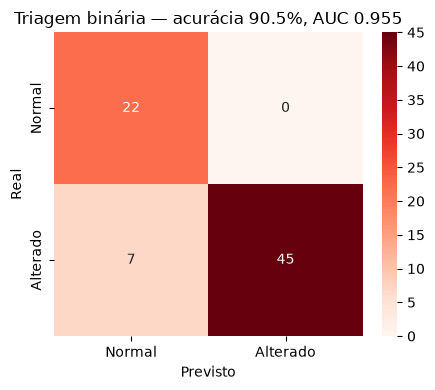


Falsos negativos (exame alterado liberado como normal): 7 de 52
É este o número que importa numa triagem: o custo de liberar um paciente alterado
é maior que o de encaminhar um normal para revisão.

Salvo em resultado_binario.json


In [6]:
# 4) Avaliação final no conjunto de teste, que nunca entrou no ajuste
clf.fit(X, yb)
p_te  = clf.predict(X_te)
pr_te = clf.predict_proba(X_te)[:, 1]

acc = accuracy_score(yb_te, p_te)
auc = roc_auc_score(yb_te, pr_te)
print(classification_report(yb_te, p_te, target_names=['Normal', 'Alterado'], digits=3))
print(f'AUC no teste: {auc:.3f}')

cm_b = confusion_matrix(yb_te, p_te)
plt.figure(figsize=(4.6, 4))
sns.heatmap(cm_b, annot=True, fmt='d', cmap='Reds',
            xticklabels=['Normal', 'Alterado'], yticklabels=['Normal', 'Alterado'])
plt.xlabel('Previsto'); plt.ylabel('Real')
plt.title(f'Triagem binária — acurácia {acc:.1%}, AUC {auc:.3f}')
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/07_binario_matriz_confusao.png', dpi=150); plt.show()

falsos_negativos = int(cm_b[1, 0])
print(f'\nFalsos negativos (exame alterado liberado como normal): {falsos_negativos} '
      f'de {int(cm_b[1].sum())}')
print('É este o número que importa numa triagem: o custo de liberar um paciente alterado')
print('é maior que o de encaminhar um normal para revisão.')

res_bin = {'modelo': 'binario_resnet_logistica', 'conjunto': 'teste',
           'acuracia': float(acc), 'auc': float(auc),
           'recall_alterado': float(cm_b[1, 1] / cm_b[1].sum()),
           'falsos_negativos': falsos_negativos,
           'cv_acuracia_media': float(cv.acuracia.mean()),
           'cv_acuracia_desvio': float(cv.acuracia.std())}
with open(f'{OUT_DIR}/resultado_binario.json', 'w', encoding='utf-8') as fh:
    json.dump(res_bin, fh, ensure_ascii=False, indent=2)
print('\nSalvo em resultado_binario.json')

### O que a comparação entre as duas formulações diz

Não é que o problema binário seja "mais fácil" e por isso o número subiu. São duas perguntas
clínicas diferentes, e os dados respondem uma delas com confiança e a outra não.

A formulação de quatro classes exige distinguir infarto agudo de infarto prévio a partir de 21
exemplos de treino. A binária exige separar traçado normal de traçado alterado, com 349
exemplos do lado alterado. **A segunda é a decisão de triagem** — a que determina se o paciente
espera ou é visto — e é a que este dataset sustenta.

Reportamos as duas. A de quatro classes porque é o que o enunciado pede e porque o resultado
ruim é informação legítima sobre o limite dos dados; a binária porque é a que teria utilidade
se alguém levasse isto adiante.

## 2.5 Protótipo — Assistente Cardiológico Virtual (interface web com Gradio)

A interface recebe a imagem de um ECG, aplica **o mesmo pré-processamento do treino** e mostra:

- a probabilidade de cada uma das 4 classes;

- uma leitura em linguagem simples.



Quando a confiança do modelo fica abaixo de 60%, o protótipo sinaliza **revisão humana obrigatória**. É uma prática de governança: o modelo apoia a decisão clínica, mas não a substitui.



Use as imagens de exemplo (tiradas do conjunto de teste) ou envie outra. O link público gerado (`share=True`) pode ser aberto no celular para a demonstração.

In [ ]:
!pip -q install gradio

In [ ]:
import gradio as gr

LIMIAR_CONFIANCA = 0.60
ORIENTACAO = {
    'Normal': 'Traçado compatível com ECG normal.',
    'Batimento_anormal': 'Padrão compatível com alteração do ritmo/batimento. Recomenda-se avaliação cardiológica.',
    'Historico_IAM': 'Padrão compatível com sinais de infarto prévio. Recomenda-se acompanhamento cardiológico.',
    'IAM': '⚠️ Padrão compatível com infarto agudo. Em um cenário real, isso exigiria avaliação médica imediata.',
}

def assistente(img):
    if img is None:
        return {}, 'Envie a imagem de um ECG.'
    x = np.expand_dims(np.array(preprocess_pil(img), dtype='float32'), 0)
    probs = best.predict(x, verbose=0)[0]
    top = CLASSES[int(probs.argmax())]
    conf = float(probs.max())
    texto = f'### Resultado mais provável: **{DISPLAY[top]}** ({conf:.0%})\n\n{ORIENTACAO[top]}'
    if conf < LIMIAR_CONFIANCA:
        texto += '\n\n🔎 **Confiança baixa:** o modelo está em dúvida. Revisão humana obrigatória.'
    texto += '\n\n---\n_Protótipo acadêmico (FIAP — CardioIA). Não substitui avaliação médica._'
    return {DISPLAY[c]: float(p) for c, p in zip(CLASSES, probs)}, texto

exemplos = [[test_df[test_df.label == c].path.iloc[0]] for c in CLASSES]

# O parâmetro que desliga o botão de flag mudou de nome entre o Gradio 4 e o 5
# ('allow_flagging' virou 'flagging_mode'). Em vez de fixar uma versão do Gradio só
# por causa disso, detectamos qual nome a instalação aceita.
import inspect
_param = ('flagging_mode' if 'flagging_mode' in inspect.signature(gr.Interface).parameters
          else 'allow_flagging')

demo = gr.Interface(
    fn=assistente,
    inputs=gr.Image(type='pil', label='Imagem do ECG (12 derivações)'),
    outputs=[gr.Label(num_top_classes=4, label='Probabilidades por classe'),
             gr.Markdown(label='Leitura do assistente')],
    title='🫀 CardioIA — Assistente Cardiológico Virtual',
    description=f'Classificação de ECG em 4 classes com {best_name}. Envie uma imagem ou use um exemplo abaixo.',
    examples=exemplos,
    **{_param: 'never'},
)
demo.launch(share=True)

## 3. Conclusões e limitações
- **Esperado:** o Transfer Learning tende a superar a CNN do zero com tão poucas imagens, porque reaproveita detectores de bordas e texturas aprendidos no ImageNet. Os números finais estão na tabela da seção 2.3.
- **Recall de IAM:** é a métrica mais crítica do ponto de vista clínico. Um falso negativo de infarto custa muito mais que um falso positivo.

**Limitações:**
- O dataset é pequeno e vem de um único hospital.
- Os exames são impressões escaneadas, sem metadados demográficos.
- O redimensionamento para 224×224 perde parte do detalhe fino do traçado.

**Próximos passos:**
- Validação cruzada.
- Mapas de ativação (Grad-CAM) para explicar o que o modelo observa.
- Testes com um dataset externo.
- Análise de vieses (Ir Além 1).
- Backend Flask com o modelo salvo e app em React Native (Ir Além 2).

Todos os prints de métricas e gráficos ficam em `/content/outputs` e podem ser baixados para o repositório.

In [ ]:
# Empacota prints, métricas e modelo. No Colab, baixa; localmente, só informa onde ficou.
destino = os.path.join(BASE_DIR, 'cardioia_fase4_outputs')
caminho = shutil.make_archive(destino, 'zip', OUT_DIR)
print('Artefatos empacotados em:', caminho)

if EM_COLAB:
    from google.colab import files
    files.download(caminho)
else:
    print('\nRodando localmente: os arquivos já estão em', OUT_DIR)
    print('Nada a baixar — basta commitar o conteúdo de outputs/ (menos o .keras, '
          'que está no .gitignore por ultrapassar o limite do GitHub).')